In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_shampoo = pd.read_csv('shampo sales.csv')
df_shampoo

,Month,Sales
0,1-01,266.0
1,1-02,145.9
2,1-03,183.1
3,1-04,119.3
4,1-05,180.3
5,1-06,168.5
6,1-07,231.8
7,1-08,224.5
8,1-09,192.8
9,1-10,122.9


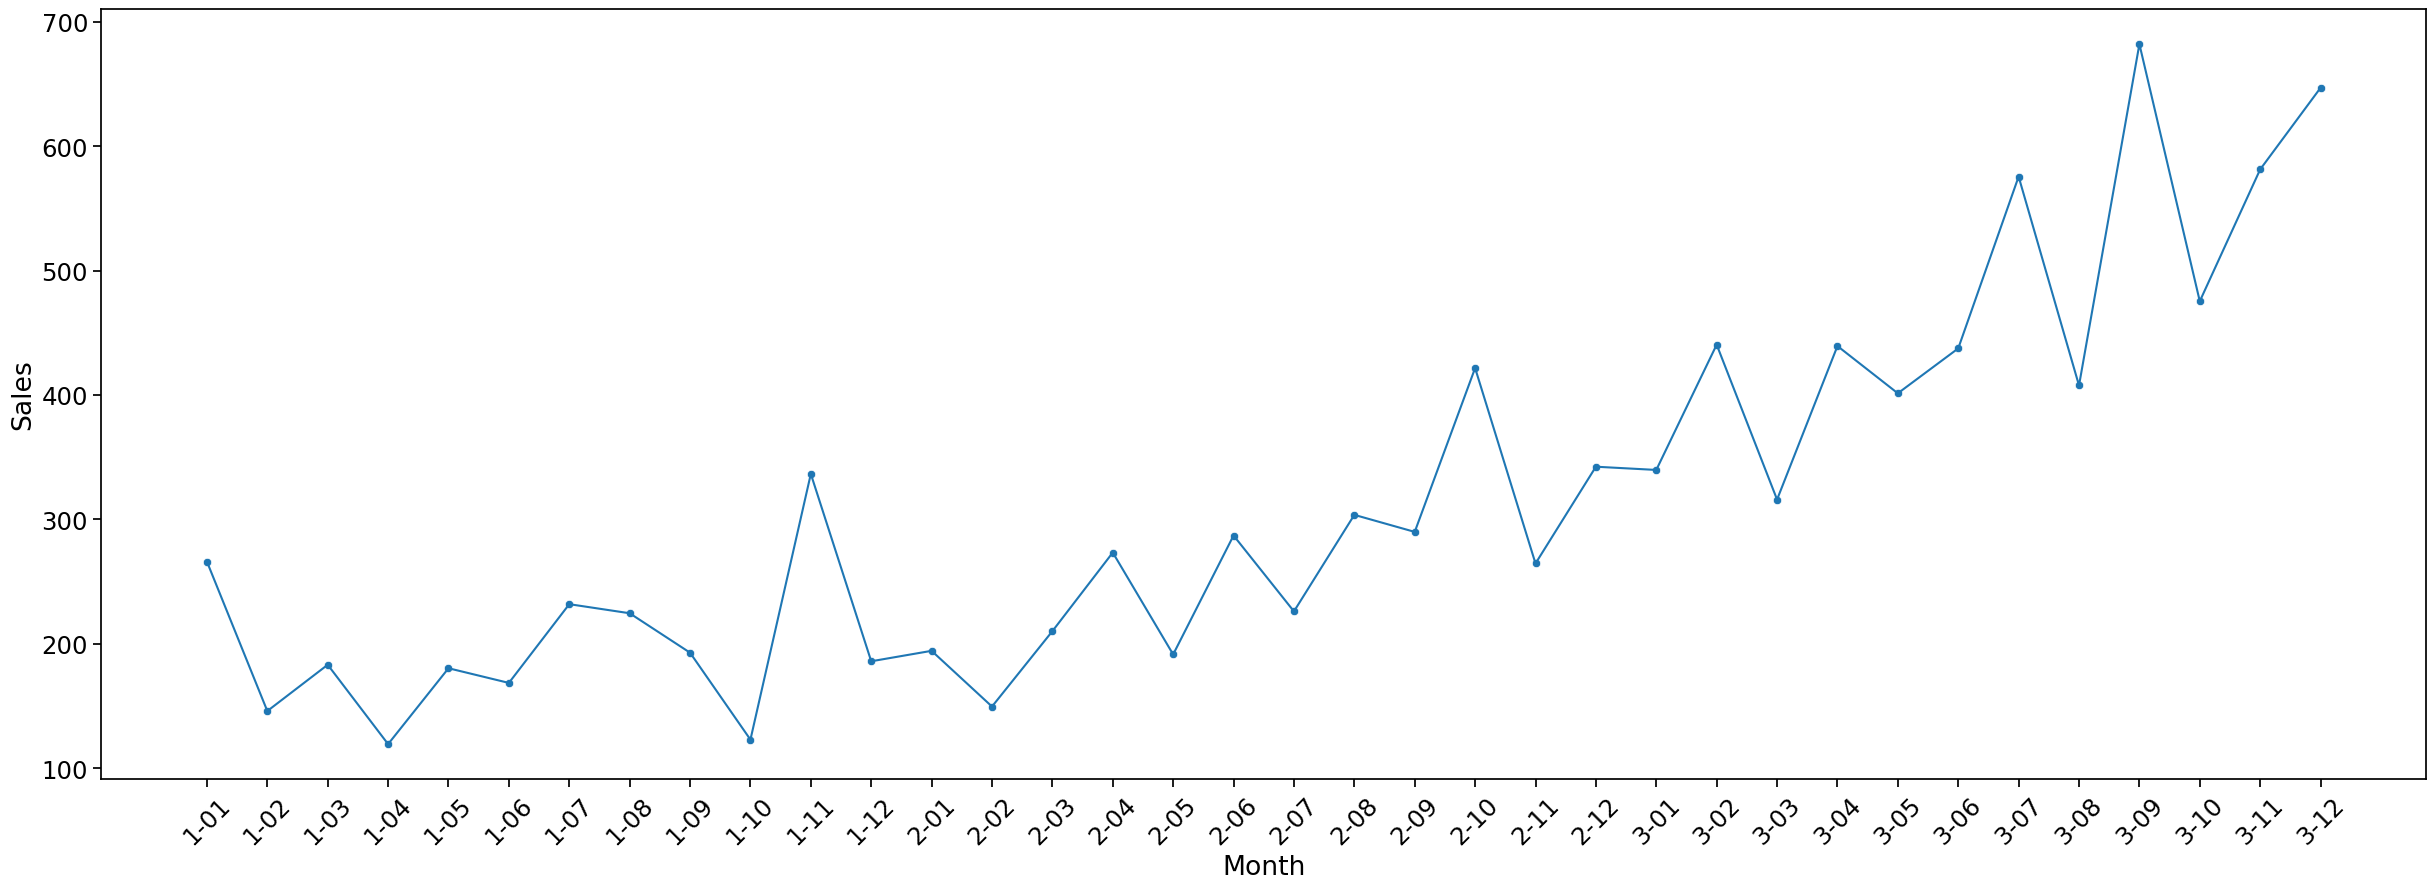

In [3]:
# see the trend
plt.figure(figsize = (30,10))

sns.set_context(context = 'notebook', font_scale=1.6)

sns.scatterplot(x = 'Month' , y = 'Sales', data = df_shampoo)
sns.lineplot(x = 'Month', y = 'Sales', data = df_shampoo)

plt.xticks(rotation=45)

plt.show()

In [4]:
url='https://raw.githubusercontent.com/jenfly/opsd/master/opsd_germany_daily.csv'
df = pd.read_csv(url)
df

,Date,Consumption,Wind,Solar,Wind+Solar
0,2006-01-01,1069.18400,NaN,NaN,NaN
1,2006-01-02,1380.52100,NaN,NaN,NaN
2,2006-01-03,1442.53300,NaN,NaN,NaN
3,2006-01-04,1457.21700,NaN,NaN,NaN
4,2006-01-05,1477.13100,NaN,NaN,NaN
...,...,...,...,...,...
4378,2017-12-27,1263.94091,394.507,16.530,411.037
4379,2017-12-28,1299.86398,506.424,14.162,520.586
4380,2017-12-29,1295.08753,584.277,29.854,614.131
4381,2017-12-30,1215.44897,721.247,7.467,728.714


In [5]:
import plotly.graph_objects as go

fig = go.Figure([go.Scatter(name = 'true',x=df['Date'], y=df['Consumption'])])
fig.update_xaxes(rangeslider_visible=True)
fig.show()

In [6]:
from pylab import rcParams
rcParams['figure.figsize'] = 20, 10

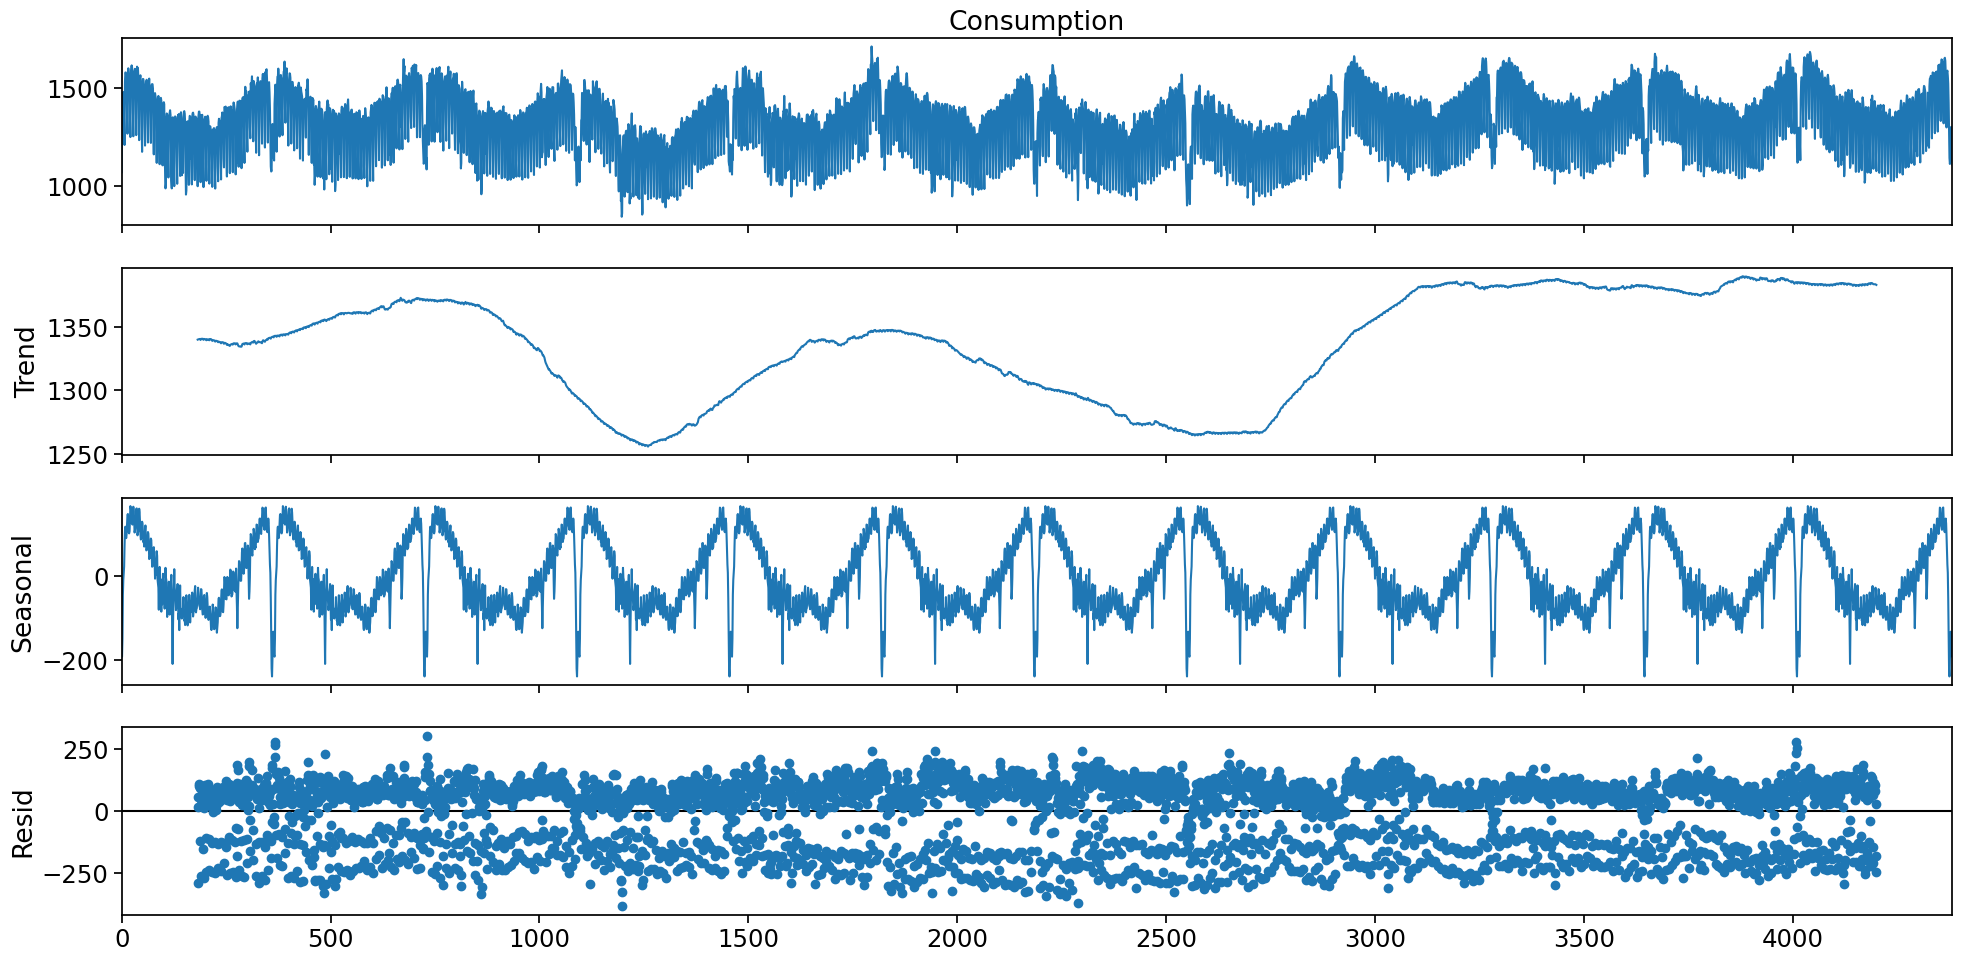

In [7]:
from pandas import Series
from statsmodels.tsa.seasonal import seasonal_decompose

series = df['Consumption']
result = seasonal_decompose(series, model='additive', period = 365)
result.plot()
plt.show()

In [8]:
df_shampoo_stationare = df_shampoo.copy() 

In [9]:
df_shampoo_stationare['Sales_Stationary_1'] = df_shampoo_stationare['Sales'].diff(1)
df_shampoo_stationare['Sales_Stationary_2'] = df_shampoo_stationare['Sales'].diff(2)

In [10]:
df_shampoo_stationare.head()

,Month,Sales,Sales_Stationary_1,Sales_Stationary_2
0,1-01,266.0,NaN,NaN
1,1-02,145.9,-120.1,NaN
2,1-03,183.1,37.2,-82.9
3,1-04,119.3,-63.8,-26.6
4,1-05,180.3,61.0,-2.8


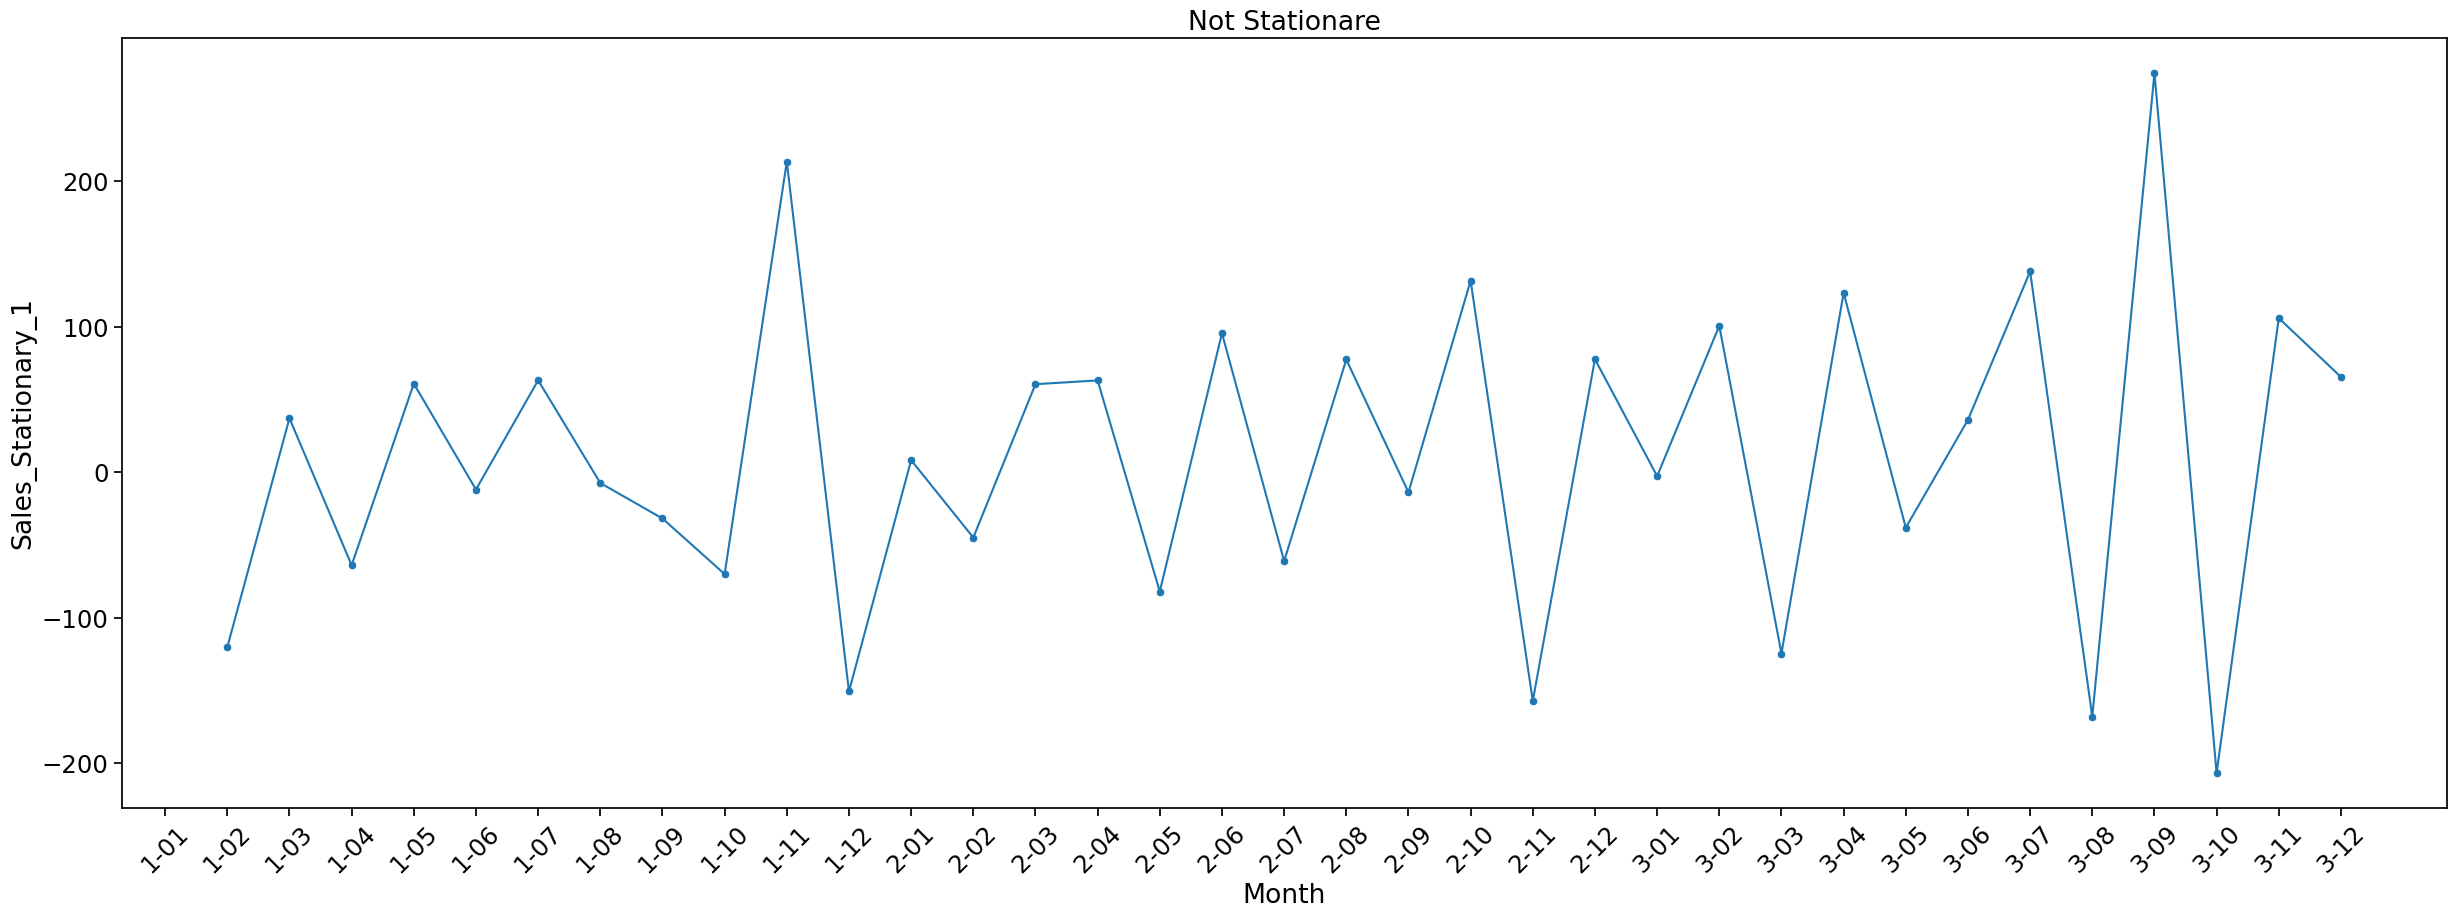

In [11]:
plt.figure(figsize = (30,10))

sns.set_context(context = 'notebook', font_scale=1.6)

sns.scatterplot(x = 'Month' , y = 'Sales_Stationary_1', data = df_shampoo_stationare)
sns.lineplot(x = 'Month', y = 'Sales_Stationary_1', data = df_shampoo_stationare)

plt.title('Not Stationare')
plt.xticks(rotation=45)

plt.show()

In [12]:
df_shampoo_ar = df_shampoo.copy() 

In [13]:
# ARIMA(2,0,0), p = 2
df_shampoo_ar['lag_1_Sales'] = df_shampoo_ar['Sales'].shift(1)
df_shampoo_ar['lag_2_Sales'] = df_shampoo_ar['Sales'].shift(2)

In [14]:
df_shampoo_ar.head()

,Month,Sales,lag_1_Sales,lag_2_Sales
0,1-01,266.0,NaN,NaN
1,1-02,145.9,266.0,NaN
2,1-03,183.1,145.9,266.0
3,1-04,119.3,183.1,145.9
4,1-05,180.3,119.3,183.1


In [15]:
# ARIMA(1,1,0), p = 1, d = 1
df_shampoo_i = df_shampoo.copy()

In [16]:
df_shampoo_i['lag_1_Sales'] = df_shampoo_i['Sales'].shift(1)
df_shampoo_i['Sales_Stationary'] = df_shampoo_i['Sales'] - df_shampoo_i['lag_1_Sales']
df_shampoo_i['lag_1_Sales_Stationary'] = df_shampoo_i['Sales_Stationary'].shift(1)
df_shampoo_i.head()

,Month,Sales,lag_1_Sales,Sales_Stationary,lag_1_Sales_Stationary
0,1-01,266.0,NaN,NaN,NaN
1,1-02,145.9,266.0,-120.1,NaN
2,1-03,183.1,145.9,37.2,-120.1
3,1-04,119.3,183.1,-63.8,37.2
4,1-05,180.3,119.3,61.0,-63.8


In [17]:
# ARIMA(0,0,1), q = 1
df_shampoo_ma = df_shampoo.copy()

In [18]:
df_shampoo_ma['et = sales - mean(sales)'] = df_shampoo_ma['Sales'] - df_shampoo_ma['Sales'].mean()
df_shampoo_ma['lag_1 et = sales - mean(sales)'] = df_shampoo_ma['et = sales - mean(sales)'].shift(1)
df_shampoo_ma.drop('et = sales - mean(sales)', axis=1, inplace=True)
df_shampoo_ma.head()

,Month,Sales,lag_1 et = sales - mean(sales)
0,1-01,266.0,NaN
1,1-02,145.9,-46.6
2,1-03,183.1,-166.7
3,1-04,119.3,-129.5
4,1-05,180.3,-193.3


In [19]:
# ARIMA(1,0,1), p = 1, q = 1
df_shampoo_ma = df_shampoo.copy()

df_shampoo_ma['lag_1_Sales'] = df_shampoo_ma['Sales'].shift(1)
df_shampoo_ma.head()

,Month,Sales,lag_1_Sales
0,1-01,266.0,NaN
1,1-02,145.9,266.0
2,1-03,183.1,145.9
3,1-04,119.3,183.1
4,1-05,180.3,119.3


In [20]:
import statsmodels.api as sm
from statsmodels.api import OLS

In [21]:
sm_lm = OLS(df_shampoo_ma[1:]['Sales'], sm.add_constant(df_shampoo_ma[1:][['lag_1_Sales']]))
result = sm_lm.fit()

In [22]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.518
Model:                            OLS   Adj. R-squared:                  0.503
Method:                 Least Squares   F-statistic:                     35.42
Date:                Mon, 24 Jun 2024   Prob (F-statistic):           1.11e-06
Time:                        11:12:47   Log-Likelihood:                -211.98
No. Observations:                  35   AIC:                             428.0
Df Residuals:                      33   BIC:                             431.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          78.0456     43.525      1.793      

In [23]:
df_shampoo_ma['et_1'] = [np.nan] + list(result.resid)
df_shampoo_ma.head()

,Month,Sales,lag_1_Sales,et_1
0,1-01,266.0,NaN,NaN
1,1-02,145.9,266.0,-139.193703
2,1-03,183.1,145.9,-8.510723
3,1-04,119.3,183.1,-101.266317
4,1-05,180.3,119.3,9.394083


In [24]:
df_shampoo

,Month,Sales
0,1-01,266.0
1,1-02,145.9
2,1-03,183.1
3,1-04,119.3
4,1-05,180.3
5,1-06,168.5
6,1-07,231.8
7,1-08,224.5
8,1-09,192.8
9,1-10,122.9


In [29]:
# predict
from statsmodels.tsa.arima_model import ARIMA

model = sm.tsa.arima.ARIMA(df_shampoo['Sales'], order = (1,0,1))
model_fit = model.fit()
model_fit

In [30]:
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -211.054
Date:                Mon, 24 Jun 2024   AIC                            430.108
Time:                        11:16:35   BIC                            436.442
Sample:                             0   HQIC                           432.319
                                 - 36                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        372.7011    234.967      1.586      0.113     -87.827     833.229
ar.L1          0.9802      0.044     22.343      0.000       0.894       1.066
ma.L1         -0.5855      0.217     -2.695      0.0

In [31]:
forecast_length = 6
forecast_result = model_fit.forecast(forecast_length)

In [33]:
print('forecast value\n',forecast_result)

forecast value
 36    576.150006
37    572.126180
38    568.181937
39    564.315703
40    560.525936
41    556.811124
Name: predicted_mean, dtype: float64
